In [1]:
from collections import Counter
import itertools
import json
import geopandas as gpd
from glob import glob
import math
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau
import os

In [2]:
acc_corr = "raam30_BEDS"
res_col = "Cost_2"

In [3]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=[acc_corr])
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,28947.351633,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,30688.468786,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,29613.408700,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,29395.681764,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,31556.255500,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [4]:
# only cars
# experiment_paths = glob("../outputs/ParamTest_NoVeh/*")
# experiment_paths = glob("../outputs/ParamTest_OnlyCars/*")
experiment_paths_nv = glob("../outputs/ParamTest_NoVeh/*")
experiment_paths_oc = glob("../outputs/ParamTest_OnlyCars/*")
# print(len(experiment_paths))
experiment_paths = {'noveh': experiment_paths_nv, 'onlycars': experiment_paths_oc}

In [5]:
# params tested
cost_funcs = ["raam", "gravity"]
noveh = ['onlycars', 'noveh']
timesteps = [10, 15, 20, 25, 30]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10, 1]

In [6]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    #     print(cf, ts, tk, na)
        cf_counter[cf] +=1
        ts_counter[ts] +=1
        tk_counter[tk] +=1
        na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'gravity': 200, 'raam': 200}),
 Counter({20: 80, 10: 80, 25: 80, 15: 80, 30: 80}),
 Counter({1: 80, 2: 80, 3: 80, 5: 80, 4: 80}),
 Counter({100: 100, 10: 100, 1000: 100, 1: 100}))

In [7]:
experiment_corr = dict()
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        # join with accessibility data on GEOID
        # join the last time step's cost
        merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
    #     print(len(merged))
        corr_res = kendalltau(merged[acc_corr], merged[res_col])
        experiment_corr[k, cf, ts, tk, na] = corr_res.correlation

In [8]:
experiment_corr

{('noveh', 'gravity', 20, 1, 100): 0.6828261011733835,
 ('noveh', 'raam', 20, 1, 10): 0.902972843462178,
 ('noveh', 'raam', 10, 2, 1000): 0.791601173211141,
 ('noveh', 'gravity', 10, 3, 1): 0.736269523609389,
 ('noveh', 'gravity', 25, 5, 1000): 0.6661569944700592,
 ('noveh', 'gravity', 20, 2, 1000): 0.6715947839820045,
 ('noveh', 'raam', 15, 5, 100): 0.7595485407793002,
 ('noveh', 'gravity', 10, 5, 1000): 0.6542859920787203,
 ('noveh', 'raam', 30, 4, 100): 0.7884783217630295,
 ('noveh', 'gravity', 20, 4, 1000): 0.6764955078631403,
 ('noveh', 'raam', 25, 1, 1): 0.9179458628590541,
 ('noveh', 'raam', 20, 4, 100): 0.7905224120733946,
 ('noveh', 'raam', 30, 5, 1): 0.7751627980198582,
 ('noveh', 'gravity', 25, 3, 100): 0.7324545056801912,
 ('noveh', 'gravity', 25, 1, 1): 0.6989087381971778,
 ('noveh', 'gravity', 20, 5, 10): 0.7438139067594229,
 ('noveh', 'gravity', 30, 3, 100): 0.7331443572232136,
 ('noveh', 'gravity', 15, 3, 100): 0.7245513071302631,
 ('noveh', 'raam', 25, 5, 1): 0.7749891

In [9]:
corrs = {'raam': [], 'gravity': []}
for k, v in experiment_corr.items():
    corrs[k[1]].append(v)
print(min(corrs['raam']), min(corrs['gravity']))
print(max(corrs['raam']), max(corrs['gravity']))

0.6884729974054156 0.6283249860251965
0.9577013048219367 0.7757832014209657


In [10]:
_min = math.floor(min([min(corrs['raam']), min(corrs['gravity'])])*10)/10.0
_max = math.ceil(max([max(corrs['raam']), max(corrs['gravity'])])*10)/10.0
print(_min, _max)

0.6 1.0


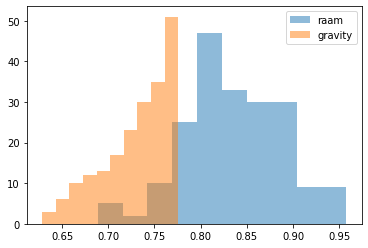

In [11]:
plt.hist(corrs['raam'], alpha=0.5, label='raam')
plt.hist(corrs['gravity'], alpha=0.5, label='gravity')
plt.legend(loc='upper right')
plt.show()

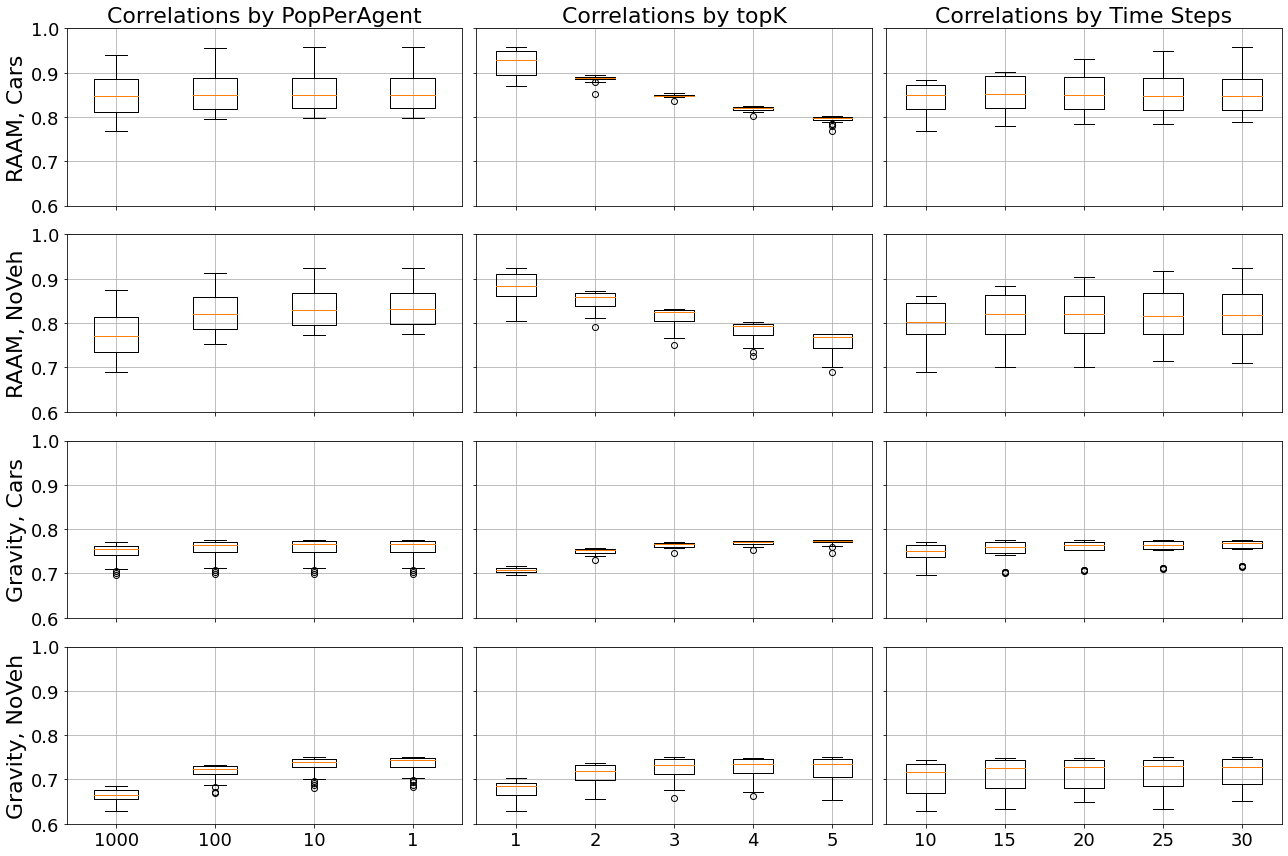

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(18, 12))
ylims = (_min, _max)
colors = [
    ["#6267f5", "#6cf562"],
    ["#f56462", "#f5a462"]
]

fsize = 22
for i, cf in enumerate(cost_funcs):
    for j, nv in enumerate(noveh):
        # get the ax for numAgents
        ax = axes[i*2 + j, 0]
        parameters = numAgents
        oparameters = (timesteps, topK)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].append(experiment_corr[nv, cf, a, b, p])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, labels=x_labels)
#         ax.set_title("Correlations by PopPerAgent")
        ax.set_ylim(*ylims)
        if not (i == 1 and j == 1):
            ax.set_xticklabels([])
        # get the ax for topk
        ax = axes[i*2 + j, 1]
        parameters = topK
        oparameters = (timesteps, numAgents)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].append(experiment_corr[nv, cf, a, p, b])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, labels=x_labels)
        if not (i == 1 and j == 1):
            ax.set_xticklabels([])
        ax.set_yticklabels([])
#         ax.set_title("Correlations by topK")
        ax.set_ylim(*ylims)
        # get the ax for timesteps
        ax = axes[i*2 + j, 2]
        parameters = timesteps
        oparameters = (topK, numAgents)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].append(experiment_corr[nv, cf, p, a, b])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, labels=x_labels)
#         ax.set_title("Correlations by Time Steps")
        ax.set_ylim(*ylims)
        if not (i == 1 and j == 1):
            ax.set_xticklabels([])
        ax.set_yticklabels([])

for ax in axes.flatten():
    ax.tick_params(axis='both', which='major', labelsize=fsize-4)
    ax.grid('on')

clabels = ["Correlations by PopPerAgent", "Correlations by topK", "Correlations by Time Steps"]
for ax, clab in zip(axes[0], clabels):
    ax.set_title(clab, fontsize=fsize)
rlabels = ["RAAM, Cars", "RAAM, NoVeh", "Gravity, Cars", "Gravity, NoVeh"]
for ax, lab in zip(axes[:, 0], rlabels):
    ax.set_ylabel(lab, fontsize=fsize)

# spacer = "     "
# fig.suptitle(f"Correlations between Results and RAAM by Parameter\nGravity{spacer}vs.{spacer}RAAM", fontsize=24)
# fig.supylabel(f"Census-based No Vehicle{spacer}vs.{spacer}Only Cars", fontsize=24)

plt.subplots_adjust(wspace=0, hspace=0)
fig.tight_layout()
plt.show()